# Data cleaning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/02-data-preparation/data-cleaning/data-cleaning-notebook.ipynb)

Companion notebook for the *Data cleaning* slides. Each idea is written first by hand
with NumPy and then with the library tool that does the same job.

**Data:** the Titanic passenger list (891 passengers).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats
from sklearn import impute
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
Z_LIMIT = 3
IQR_FACTOR = 1.5

titanic = sns.load_dataset("titanic")[["survived", "pclass", "sex", "age", "fare", "embarked"]]
titanic.head()

,survived,pclass,sex,age,fare,embarked
0,0,3,male,22.0,7.2500,S
1,1,1,female,38.0,71.2833,C
2,1,3,female,26.0,7.9250,S
3,1,1,female,35.0,53.1000,S
4,0,3,male,35.0,8.0500,S


## 1. Find the problems

Before changing anything, count what is missing.

In [2]:
titanic.isna().sum()

survived      0
pclass        0
sex           0
age         177
fare          0
embarked      2
dtype: int64

## 2. Fill missing ages with the median

Take the median of the known values $\tilde{x}_j$ and put it in every empty cell.
`fit` learns the median, `transform` fills the gaps.

In [3]:
class SimpleImputer:
    """Fill missing values with the median (or mean) of each column."""

    def __init__(self, strategy="median"):
        self.strategy = strategy

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        if self.strategy == "median":
            self.statistics_ = np.nanmedian(X, axis=0)  # median of the known values
        else:
            self.statistics_ = np.nanmean(X, axis=0)
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return np.where(np.isnan(X), self.statistics_, X)

    def fit_transform(self, X):
        return self.fit(X).transform(X)


imputer = SimpleImputer(strategy="median")
ages_by_hand = imputer.fit_transform(titanic[["age"]]).ravel()
print("median age:", imputer.statistics_[0])

median age: 28.0


In [4]:
imputer_library = impute.SimpleImputer(strategy="median")
ages_library = imputer_library.fit_transform(titanic[["age"]]).ravel()
print("same result:", np.allclose(ages_by_hand, ages_library))

same result: True


## 3. Flag outliers

Two rules from the slides, applied to the fare:

- z-score: flag $x$ when $|z| = |x - \bar{x}| / s > 3$.
- IQR fences: flag $x$ outside $[Q_1 - 1.5\,\text{IQR},\ Q_3 + 1.5\,\text{IQR}]$ with $\text{IQR} = Q_3 - Q_1$.

In [5]:
fares = titanic["fare"].to_numpy()

mean = fares.mean()  # x̄
std = fares.std()  # s
z_by_hand = (fares - mean) / std  # z = (x - x̄) / s
z_outliers = np.abs(z_by_hand) > Z_LIMIT

q1, q3 = np.percentile(fares, [25, 75])
iqr = q3 - q1
low_fence = q1 - IQR_FACTOR * iqr
high_fence = q3 + IQR_FACTOR * iqr
iqr_outliers = (fares < low_fence) | (fares > high_fence)

print("z-score outliers:", np.sum(z_outliers))
print("IQR outliers:", np.sum(iqr_outliers))

z-score outliers: 20
IQR outliers: 116


In [6]:
print("same z-scores:", np.allclose(z_by_hand, stats.zscore(fares)))

same z-scores: True


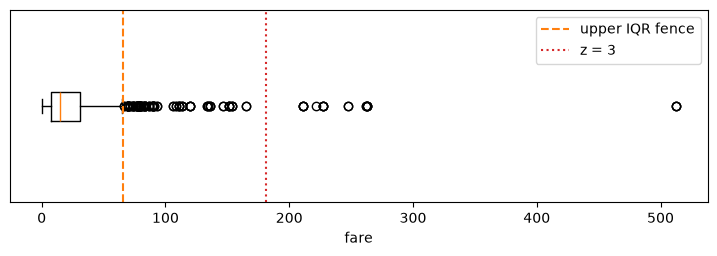

In [7]:
fig, axis = plt.subplots(figsize=(9, 2.5))
axis.boxplot(fares, orientation="horizontal", whis=IQR_FACTOR)
axis.axvline(high_fence, color="tab:orange", linestyle="--", label="upper IQR fence")
z_limit_fare = mean + Z_LIMIT * std  # the fare where z = 3
axis.axvline(z_limit_fare, color="tab:red", linestyle=":", label="z = 3")
axis.set_xlabel("fare")
axis.set_yticks([])
axis.legend()
plt.show()

## 4. Learn the fill value from training rows only

The median is a statistic learned from data, so it must come from the training rows.
The same value then fills the gaps in the test rows.

In [8]:
train, test = train_test_split(titanic, test_size=0.2, random_state=RANDOM_STATE)

imputer_by_hand = SimpleImputer(strategy="median").fit(train[["age"]])
test_ages_by_hand = imputer_by_hand.transform(test[["age"]]).ravel()

In [9]:
imputer_library = impute.SimpleImputer(strategy="median").fit(train[["age"]])
test_ages_library = imputer_library.transform(test[["age"]]).ravel()
same_result = np.allclose(test_ages_by_hand, test_ages_library)
print("learned median:", imputer_library.statistics_[0], "| same result:", same_result)

learned median: 28.0 | same result: True


## Exercises

1. Fill `embarked` with its most frequent value, by hand and with `impute.SimpleImputer(strategy="most_frequent")`.
2. Fill each missing age with the median age of the passenger's class (`pclass`).
3. Change the IQR factor from 1.5 to 3. How many fares are still flagged?